# MODELIZACIÓN CLASIFICACIÓN PROBABILITY OF DEFAULT

## IMPORTAR PAQUETES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
import janitor
import os
from pathlib import Path
import openpyxl
import sqlalchemy as sa

# Desactivar notación científica
pd.set_option('display.float_format', lambda x: '%.3f' % x)
np.set_printoptions(suppress=True)

# Cargar variables de entorno
load_dotenv()

print("✅ Librerías importadas correctamente")

✅ Librerías importadas correctamente


## IMPORTAR DATOS

In [2]:
df = pd.read_pickle('../02_datos/03_Entrenamiento/df_tablon_pd.pkl')

In [3]:
x = df.drop(columns='target_pd')
y = df.target_pd

## MODELIZAR

### Reservar el dataset de valicación

In [4]:
from sklearn.model_selection import train_test_split
train_x, val_x, train_y, val_y = train_test_split(x, y, test_size=0.3)

### Crear el pipe line y el diccionario de algoritmos, parámetros y valores a testar

Modificar para dejar solo los algoritmos que se quieran testar.

Modificar los parámetros

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

pipe = Pipeline([('algoritmo', LogisticRegression())])

grid = [{'algoritmo' : [LogisticRegression(solver = 'saga')],
         'algoritmo__l1_ratio' : [0, 0.5, 1],
         'algoritmo__C' : [0.01, 0.25, 0.5, 0.75, 1]}
         ]

### Optimizar los hiper parametros

Elegir si se quiere usar grid search o random search

Comentar la opción que no se vaya a usar

### Con grid search

In [6]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(estimator = pipe,
                           param_grid = grid,
                           cv = 5,
                           scoring = 'roc_auc',
                           verbose = 0,
                           n_jobs = -1)

modelo = grid_search.fit(train_x, train_y)

In [7]:
salida = pd.DataFrame(grid_search.cv_results_).sort_values(by = 'rank_test_score').reset_index(drop = True).head(5)
salida

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_algoritmo,param_algoritmo__C,param_algoritmo__l1_ratio,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,1.906,0.169,0.021,0.005,LogisticRegression(solver='saga'),1.000,1.000,{'algoritmo': LogisticRegression(solver='saga'...,0.704,0.694,0.707,0.702,0.712,0.704,0.006,1
1,7.193,0.325,0.013,0.002,LogisticRegression(solver='saga'),1.000,0.500,{'algoritmo': LogisticRegression(solver='saga'...,0.704,0.694,0.707,0.702,0.712,0.704,0.006,2
2,2.039,0.218,0.020,0.003,LogisticRegression(solver='saga'),0.750,1.000,{'algoritmo': LogisticRegression(solver='saga'...,0.704,0.695,0.706,0.702,0.712,0.704,0.006,3
3,6.764,0.218,0.019,0.001,LogisticRegression(solver='saga'),1.000,0.000,{'algoritmo': LogisticRegression(solver='saga'...,0.704,0.694,0.706,0.702,0.712,0.704,0.006,4
4,7.179,0.278,0.020,0.002,LogisticRegression(solver='saga'),0.750,0.500,{'algoritmo': LogisticRegression(solver='saga'...,0.704,0.694,0.706,0.702,0.712,0.704,0.006,5


Vemos que el resultado del auc es el mismo en todas las primeras configuraciones

Y reentrenamos el modelo con esa configuración

In [8]:
# Instanciar
rl = LogisticRegression(solver = 'saga', C = 1, l1_ratio = 1)
# Entrenamos
rl.fit(train_x, train_y)

,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'saga'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization stren

Podemos revisar los coeficientes para ver los que son cero y las variables más importantes

In [10]:
coeficientes = pd.DataFrame(data = rl.coef_, columns = rl.feature_names_in_).stack().droplevel(level = 0).sort_values()
coeficientes

tipo_interes_mms                       -2.476
ingresos_mms                           -1.730
principal_mms                          -1.382
ingresos_verificados_Not Verified      -0.259
num_cuotas_ 36 months                  -0.248
finalidad_car                          -0.133
finalidad_house                        -0.130
DTI_mms                                -0.123
finalidad_other                        -0.102
finalidad_credit_card                  -0.063
antigüedad_empleo_oe_mms               -0.057
vivienda_MORTGAGE                      -0.057
finalidad_vacation                     -0.026
vivienda_OWN                           -0.000
ingresos_verificados_Source Verified   -0.000
finalidad_medical                       0.000
num_cuotas_ 60 months                   0.005
finalidad_debt_consolidation            0.017
finalidad_moving                        0.059
ingresos_verificados_Verified           0.092
finalidad_home_improvement              0.104
num_derogatorios_bin              

## EVALUAR

### Predecir sobre validación

In [11]:
pred = rl.predict_proba(val_x)[:, 1]

### Evaluar sobre validación

In [12]:
from sklearn.metrics import roc_auc_score
roc_auc_score(val_y, pred)

0.6984343314601551

## REPORTING DEL MODELO

### Gain Chart

In [15]:
def gain_chart(y_true, y_pred, figsize = (8, 6)):
    df_gain = pd.DataFrame({'y' : y_true, 'pred' : y_pred})
    df_gain = df_gain.sort_values('pred', ascending=False).reset_index(drop=True)

    df_gain['acumulado'] = df_gain['y'].cumsum() / df_gain['y'].sum()
    df_gain['porcentaje_muestra'] = (np.arange(len(df_gain)) + 1 ) / len(df_gain)

    plt.figure(figsize=figsize)
    plt.plot(df_gain['porcentaje_muestra'], df_gain['acumulado'], label='Modelo')
    plt.plot(df_gain['porcentaje_muestra'], df_gain['porcentaje_muestra'], '--', label = 'Aleatorio')
    plt.xlabel('Porcentaje de muestra')
    plt.ylabel('Porcentaje acumulado de positivos')
    plt.title('Gain Chart')
    plt.legend()
    plt.grid()
    plt.show()

    return df_gain

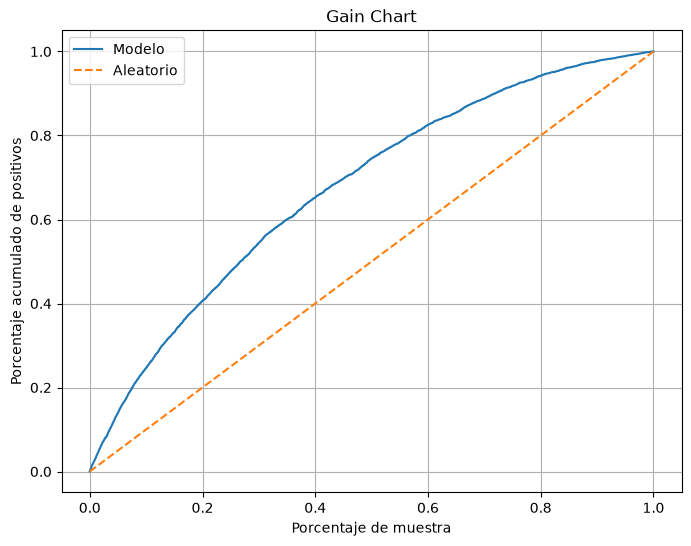

,y,pred,acumulado,porcentaje_muestra
0,1,0.732,0.000,0.000
1,0,0.731,0.000,0.000
2,1,0.707,0.000,0.000
3,0,0.701,0.000,0.000
4,0,0.695,0.000,0.000
...,...,...,...,...
41877,0,0.012,1.000,1.000
41878,0,0.012,1.000,1.000
41879,0,0.011,1.000,1.000
41880,0,0.011,1.000,1.000


In [16]:
gain_chart(val_y, pred)

### Lift Chart